# EDA – Dự đoán giá ô tô cũ (AutoScout24, Zenodo 17643343)

**Mục tiêu:** hiểu dữ liệu trước khi nghiên cứu Encoding × Scaling (tuần 2–3).
**Phạm vi:** ô tô cũ (`is_used=True`, `is_new=False`), loại `Car`, giá EUR hợp lệ. **Target:** `price` – giá chào bán (không phải giá giao dịch).

> Quy tắc tách bạch leakage: phân phối giá / số đếm / cardinality tính trên **toàn bộ dữ liệu sạch** (không dùng target để chọn biến);
> mọi quan hệ feature–giá tính trên **tập train** (`data/processed/train.parquet`). Tập test không được dùng trong notebook này.

In [1]:
import json, sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from IPython.display import Image, display, Markdown
pd.set_option('display.width', 200, 'display.max_columns', 30, 'display.float_format', '{:,.2f}'.format)
sns.set_theme(style='whitegrid')
T = ROOT / 'reports' / 'tables'
stats = json.loads((ROOT / 'reports' / 'stats.json').read_text(encoding='utf-8'))
df = pd.read_parquet(ROOT / 'data' / 'interim' / 'autoscout24_used_common.parquet')
train = pd.read_parquet(ROOT / 'data' / 'processed' / 'train.parquet')
print('clean:', df.shape, '| train:', train.shape)

clean: (94266, 41) | train: (75457, 20)


## 2. Tổng quan dữ liệu

In [2]:
raw = stats['raw']
print(f"Raw: {raw['rows']:,} dòng x {raw['cols']} cột | RAM ~{raw['ram_mb_deep']:.0f} MB | trùng toàn bộ: {raw['full_row_duplicates']} | id trùng: {raw['id_duplicates']} | dòng có VIN lặp: {raw['vin_duplicate_rows']:,}")
print('Cột rỗng 100%:', raw['all_null_columns'])
display(pd.read_csv(T / 'scope_funnel.csv'))

Raw: 118,382 dòng x 75 cột | RAM ~586 MB | trùng toàn bộ: 0 | id trùng: 0 | dòng có VIN lặp: 2,644
Cột rỗng 100%: ['fuel_cons_city_l100_km', 'fuel_cons_highway_l100_km', 'has_warranty', 'warranty']


,step,rule,rows_before,rows_after,rows_removed,reason
0,raw,start (after type/whitespace/missing-token nor...,118382,118382,0,NaN
1,used_only,is_used == True and is_new == False (NaN count...,118382,95684,22698,"new cars, pre-registered/demo cars and records..."
2,offer_type,offer_type == 'U' (or missing),95684,95681,3,offer types other than 'U' (used) are unconfirmed
3,vehicle_type,vehicle_type == 'Car',95681,95600,81,non-passenger vehicles (e.g. Transporter)
4,commercial_body_type,"body_type not in ['box', 'flatbed van', 'flatb...",95600,95407,193,commercial body types listed under vehicle_typ...
5,currency,price_currency == 'EUR',95407,95407,0,other/missing currency (no conversion performed)
6,price_not_null,price is numeric and not null,95407,95407,0,unparseable/missing target
7,price_positive,price > 0,95407,95407,0,zero/negative price
8,price_min,price >= 100 EUR,95407,95399,8,placeholder prices (e.g. price = 1)
9,content_duplicates,"drop repeated (valid VIN, price, mileage, regi...",95399,94266,1133,identical listings re-posted under a different id


In [3]:
miss = pd.DataFrame({'dtype': df.dtypes.astype(str), 'pct_missing': df.isna().mean() * 100}).sort_values('pct_missing', ascending=False)
display(miss.head(15))

,dtype,pct_missing
price_vat_rate,float64,80.91
price_net,float64,80.80
vin,str,70.93
nr_prev_owners,float64,47.01
drive_train,str,24.18
seller_company_name,str,20.98
body_color,str,12.05
engine_cc,float64,9.42
nr_seats,float64,3.65
power_kw,float64,1.30


## 3. Phân tích giá (toàn bộ dữ liệu sạch)

,statistic,value
0,count,"94,266.00"
1,mean,"54,283.43"
2,std,"119,477.53"
3,min,250.00
4,p0.1,691.33
5,p1,"1,950.00"
6,p5,"6,300.00"
7,p25,"21,590.00"
8,p50,"34,490.00"
9,p75,"65,490.00"


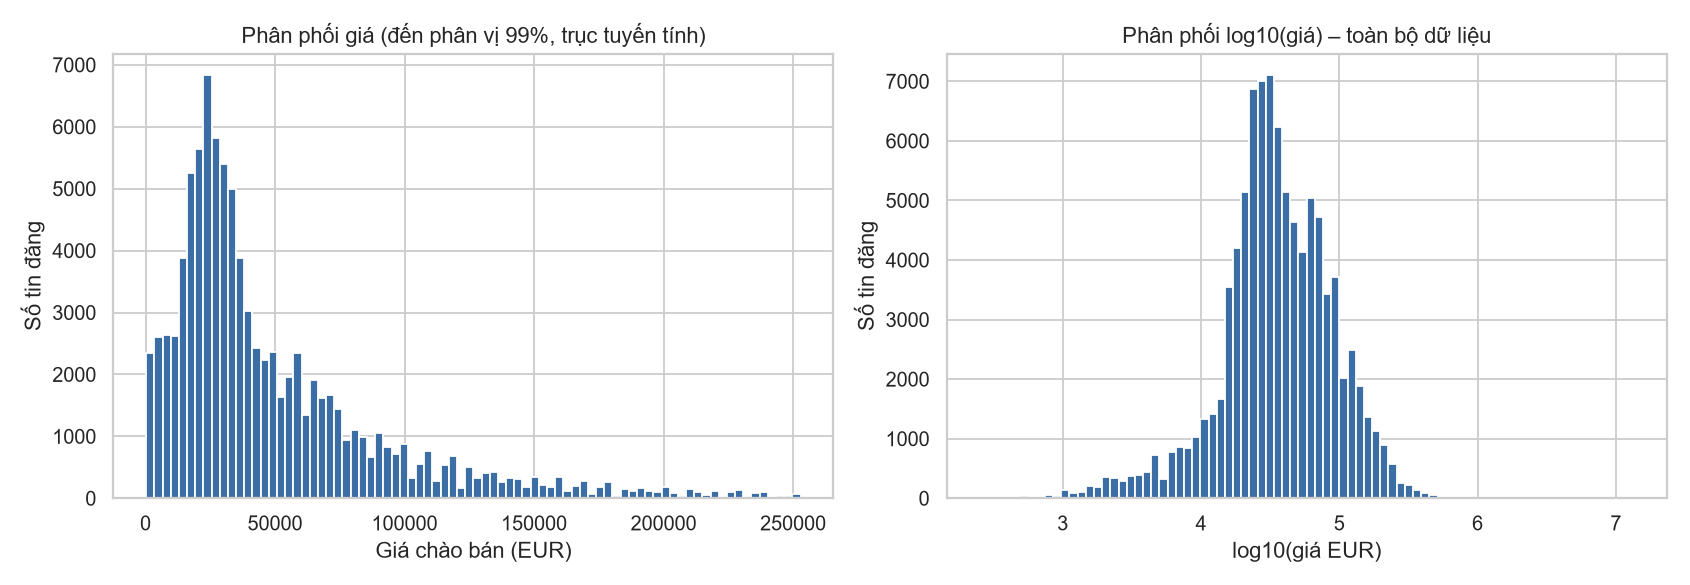

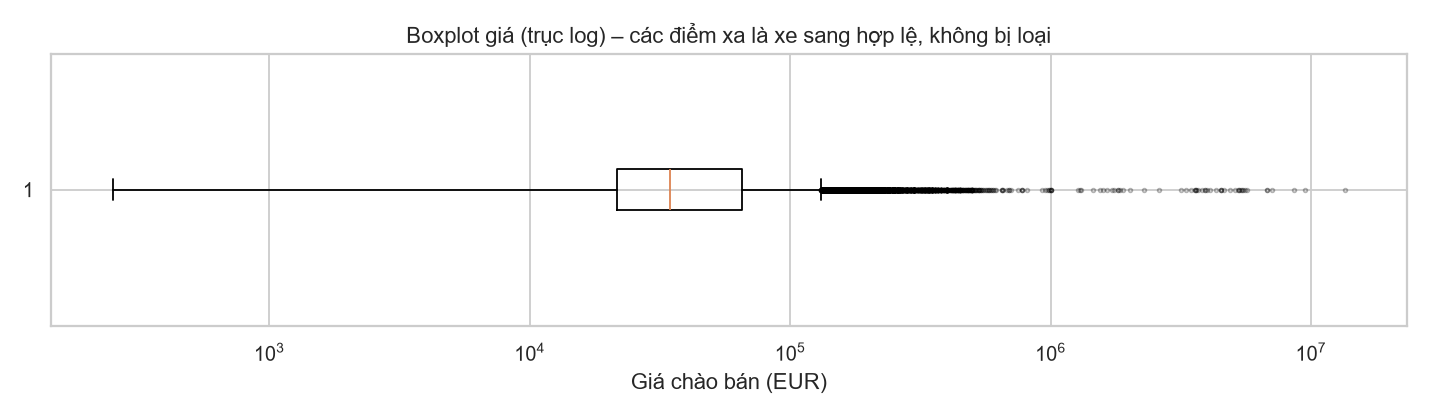

In [4]:
display(pd.read_csv(T / 'price_statistics.csv'))
display(Image(str(ROOT / 'reports/figures/price_histograms.png')))
display(Image(str(ROOT / 'reports/figures/price_boxplot.png')))

**Nhận xét:** phân phối lệch phải rất mạnh (skew trên thang EUR rất lớn, gần đối xứng sau log). Các điểm xa trong boxplot là xe sang hợp lệ (Bugatti, Rolls-Royce…) nên không bị loại; chúng sẽ chi phối RMSE. Log-transform của target là một thí nghiệm riêng ở tuần 2 (cần so sánh RMSE trên thang EUR gốc).

## 4. Thuộc tính số

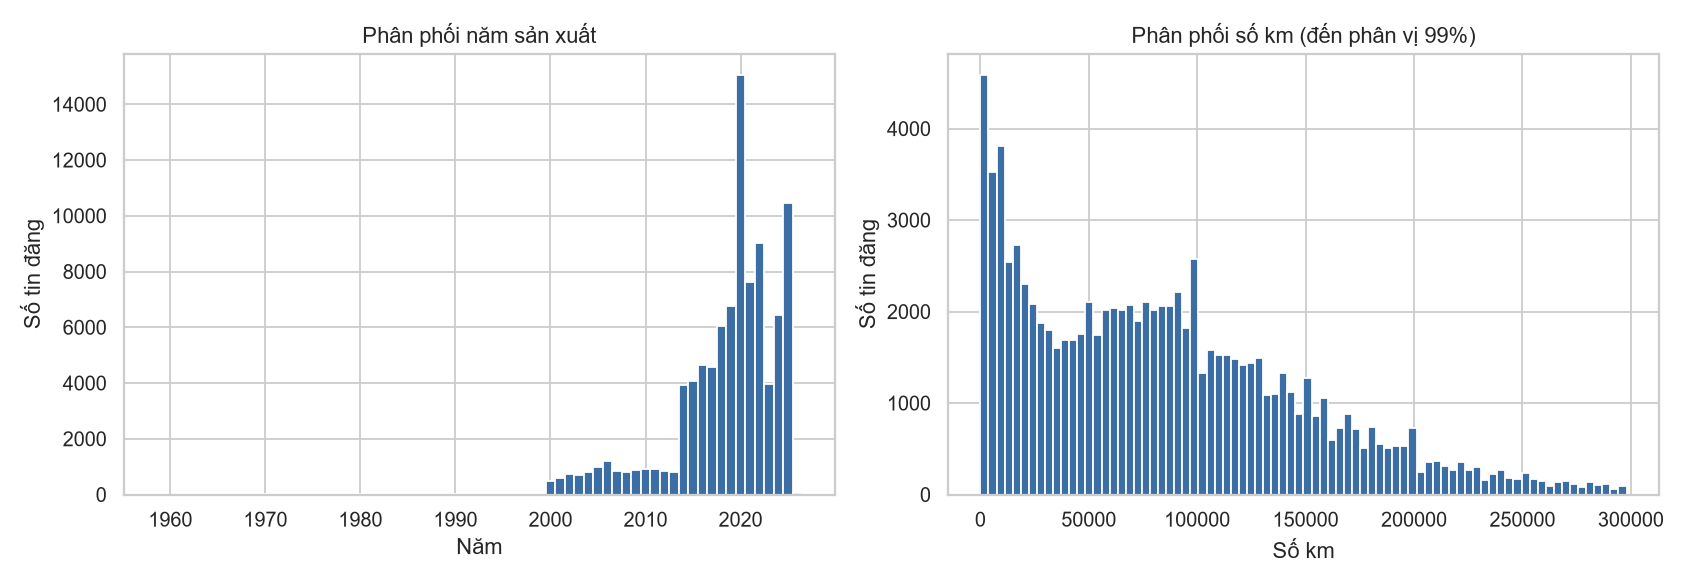

,count,mean,std,min,1%,50%,99%,max
production_year,"94,243.00","2,018.60",5.53,"1,959.00","2,001.00","2,020.00","2,025.00","2,026.00"
vehicle_age,"94,243.00",6.40,5.53,0.00,0.00,5.00,24.00,66.00
mileage_km,"94,263.00","87,028.90","69,293.50",0.00,14.00,"76,808.00","298,000.00","1,000,000.00"
power_kw,"93,041.00",205.04,105.84,10.00,61.00,184.00,480.00,"1,177.00"
engine_cc,"85,386.00","2,445.00",889.13,0.00,998.00,"1,998.00","4,806.00","8,000.00"
nr_seats,"90,825.00",4.68,0.84,1.00,2.00,5.00,7.00,9.00


In [5]:
display(Image(str(ROOT / 'reports/figures/year_mileage_distribution.png')))
display(df[['production_year','vehicle_age','mileage_km','power_kw','engine_cc','nr_seats']].describe(percentiles=[.01,.5,.99]).T)

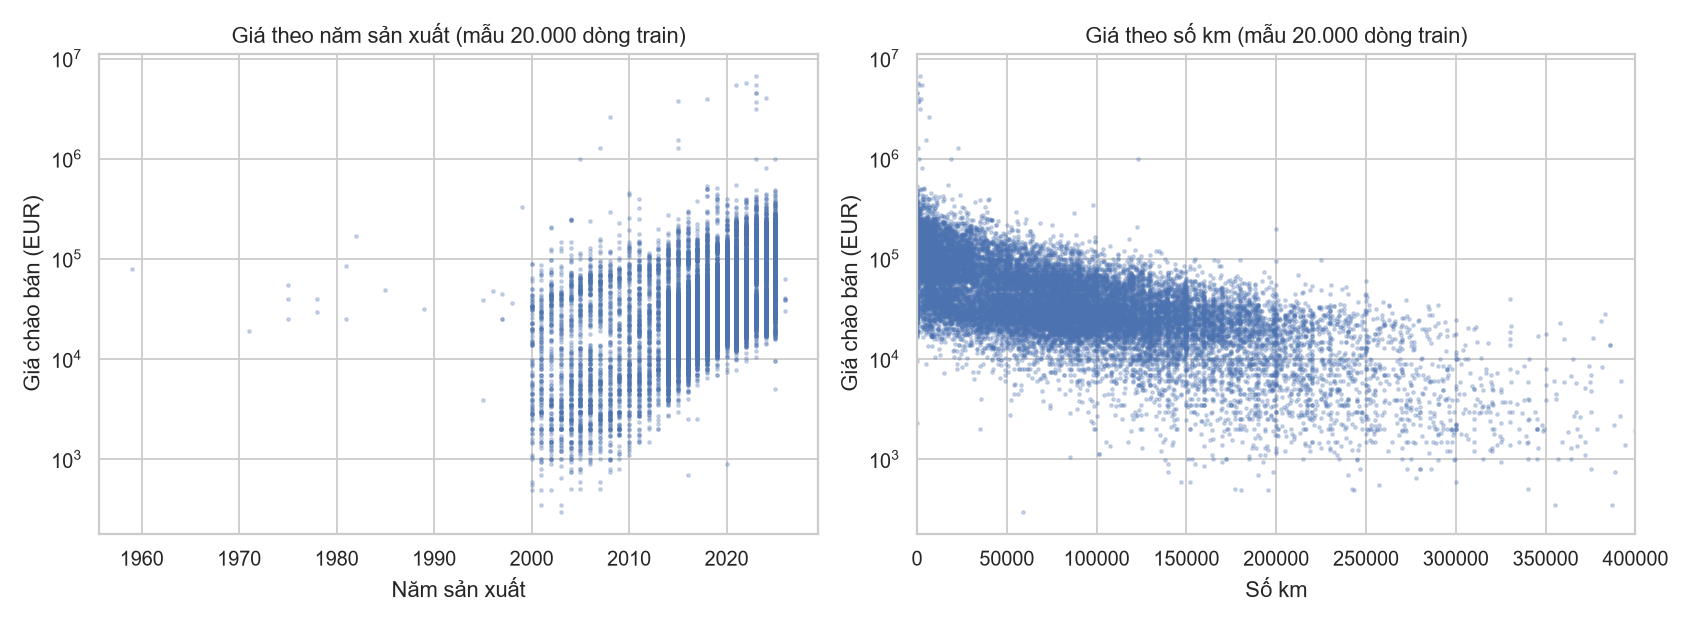

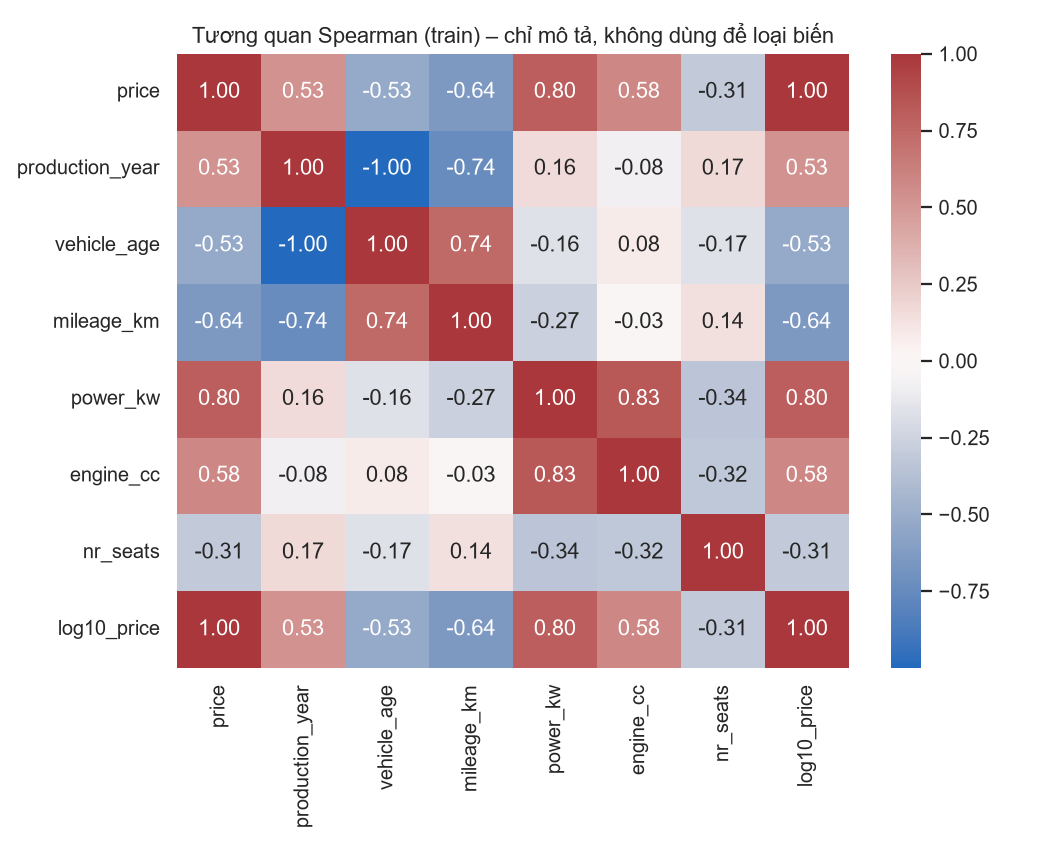

In [6]:
display(Image(str(ROOT / 'reports/figures/price_vs_year_mileage.png')))
display(Image(str(ROOT / 'reports/figures/numeric_correlation.png')))

Tương quan Spearman chỉ mô tả quan hệ đơn biến trên train, không dùng để chọn hay loại biến.

## 5. Biến phân loại

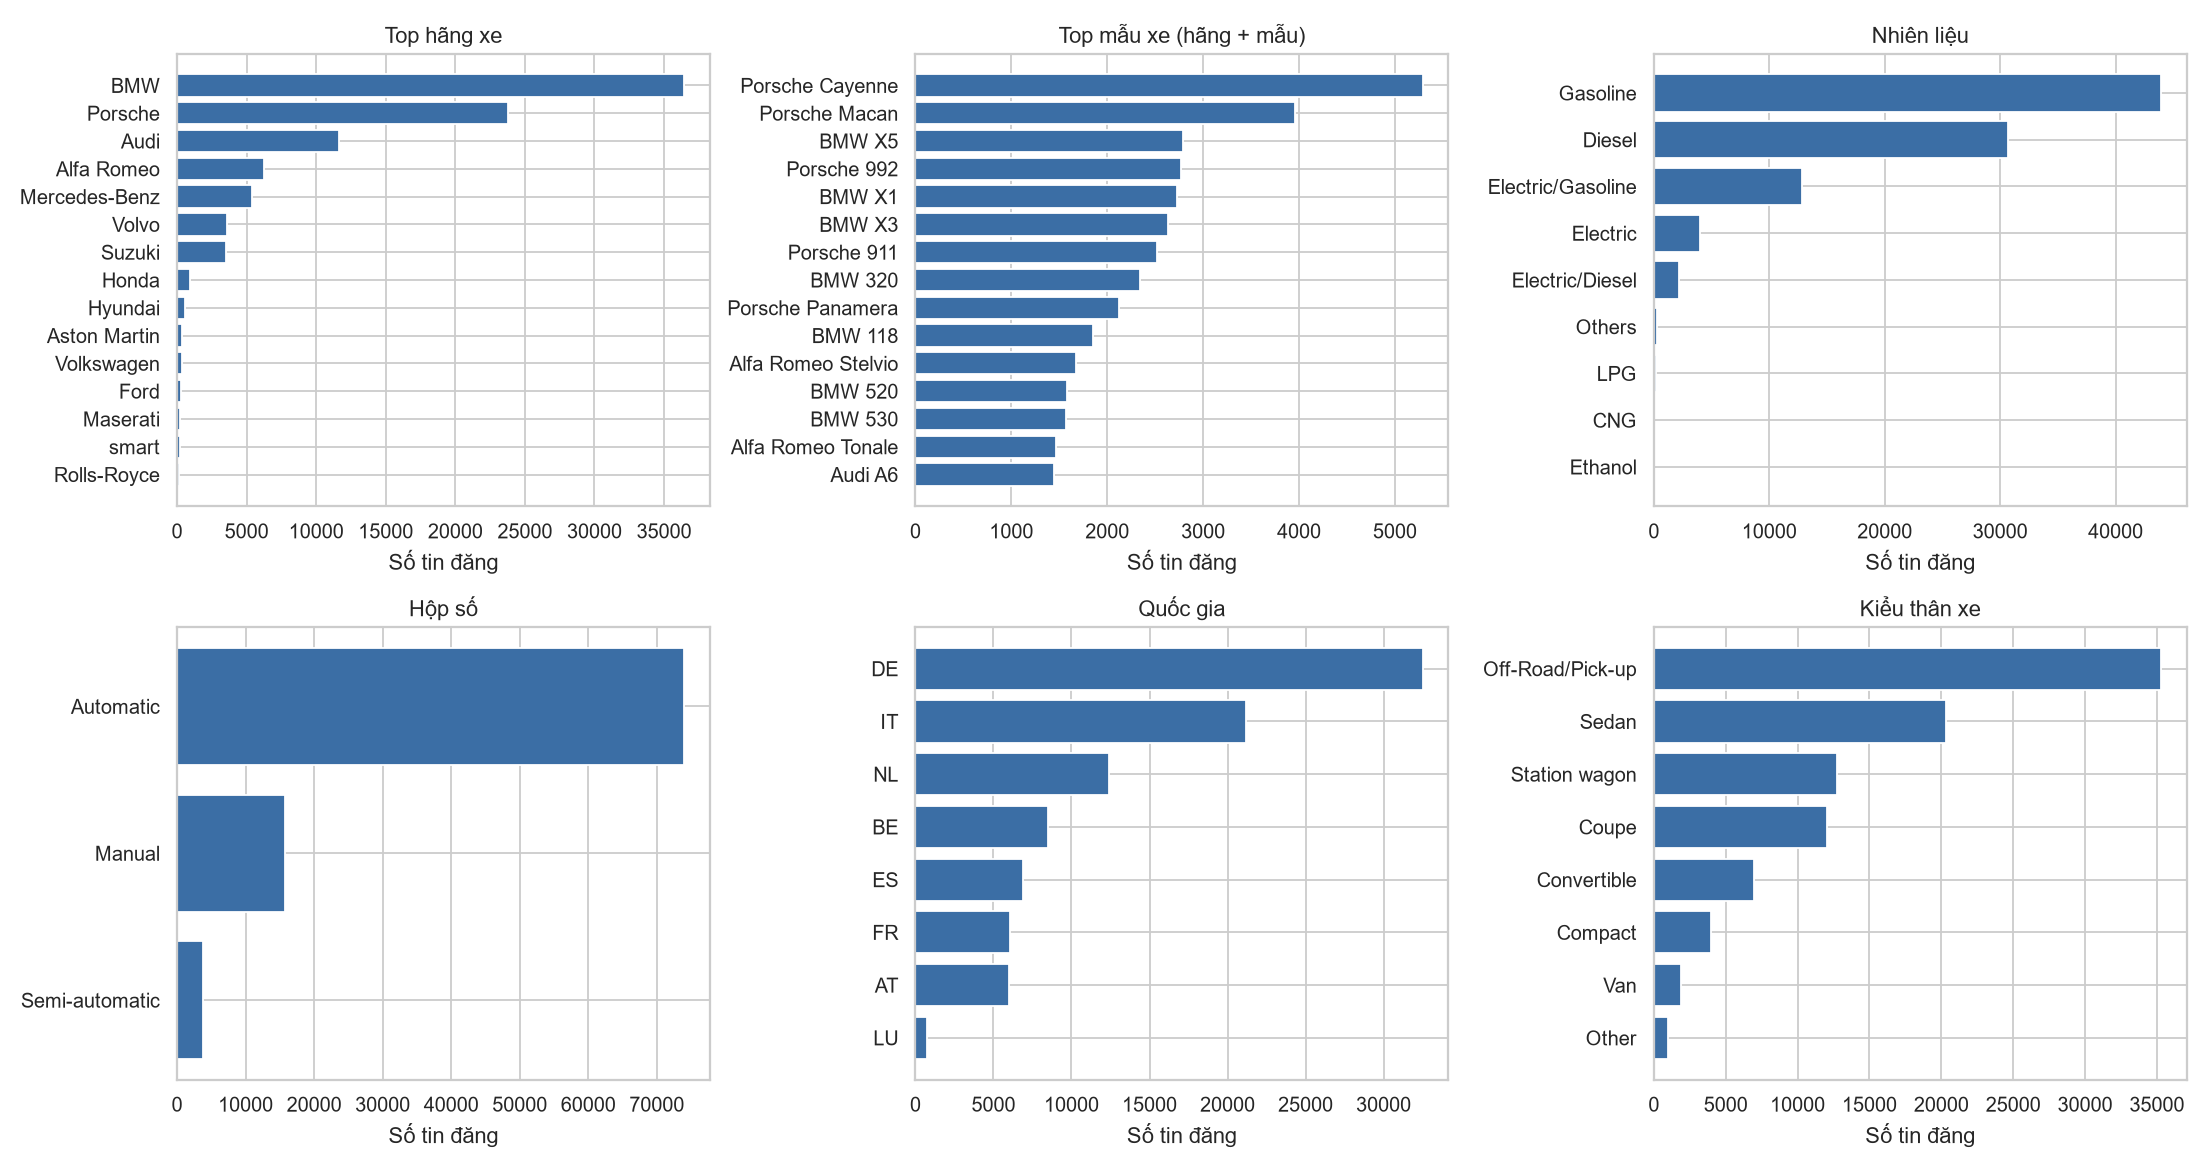

,column,n_unique,level,pct_missing,n_cat_count_eq1,n_cat_count_lt5,n_cat_count_lt10,pct_rows_in_cats_lt10
0,model_version,71015,high (>50),0.77,63854,69713,70560,88.44
1,make_model,603,high (>50),0.75,92,181,249,0.83
2,model,602,high (>50),0.75,91,180,248,0.83
3,brand,25,medium (11-50),0.00,0,0,1,0.01
4,body_color,14,medium (11-50),12.05,0,0,0,0.00
5,fuel_type,9,low (<=10),0.06,0,0,1,0.01
6,body_type,8,low (<=10),0.00,0,0,0,0.00
7,country_code,8,low (<=10),0.01,0,0,0,0.00
8,transmission,3,low (<=10),0.81,0,0,0,0.00
9,drive_train,3,low (<=10),24.18,0,0,0,0.00


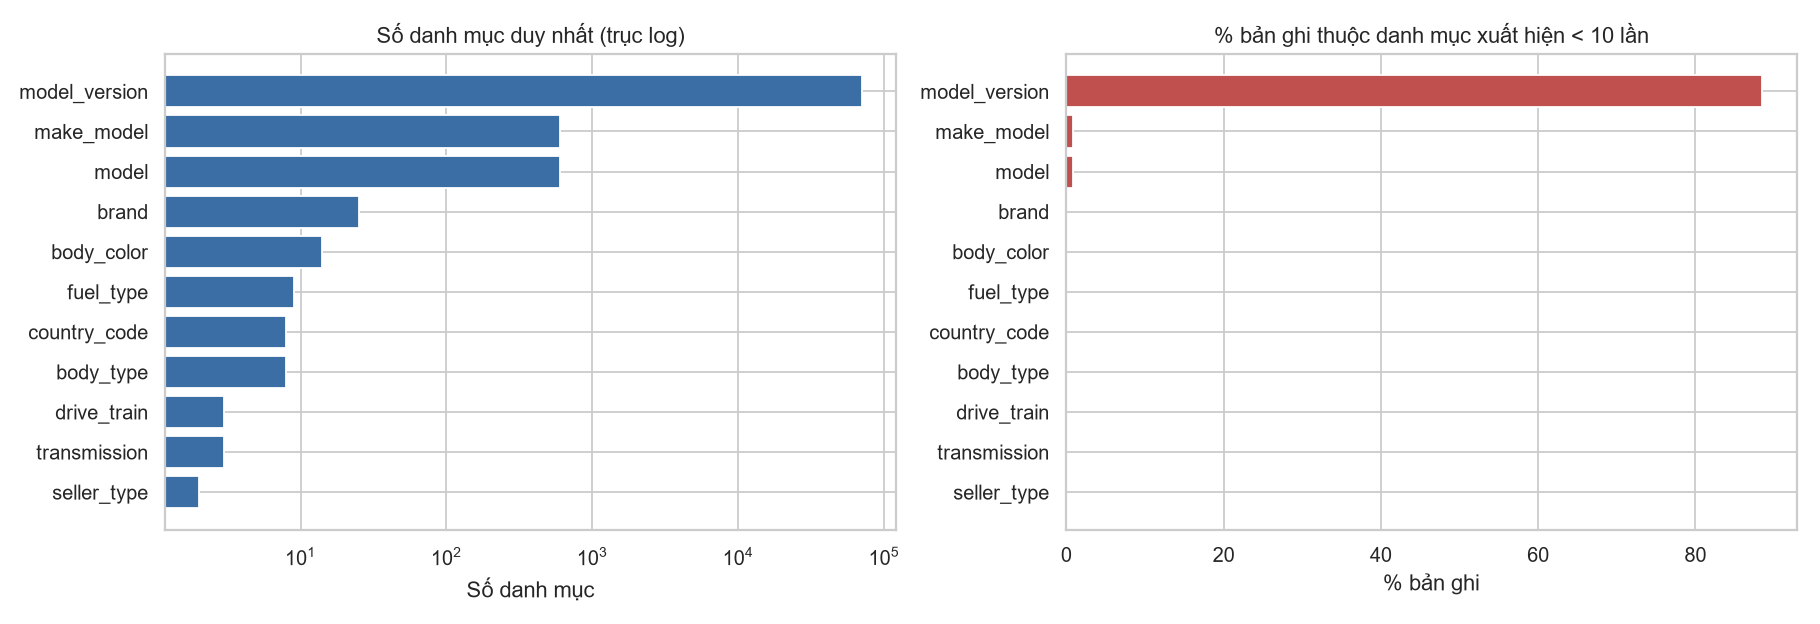

In [7]:
display(Image(str(ROOT / 'reports/figures/categorical_counts.png')))
card = pd.read_csv(T / 'categorical_cardinality.csv')
display(card[['column','n_unique','level','pct_missing','n_cat_count_eq1','n_cat_count_lt5','n_cat_count_lt10','pct_rows_in_cats_lt10']])
display(Image(str(ROOT / 'reports/figures/cardinality.png')))

In [8]:
mvs = stats['make_model']['model_version_summary']
print({k: v for k, v in mvs.items()})
display(pd.read_csv(T / 'unseen_categories_test_vs_train.csv'))

{'n_unique': 71015, 'n_non_missing': 93538, 'n_missing': 728, 'n_singletons': 63854, 'pct_cats_singleton': 89.92, 'n_lt5': 69713, 'n_lt10': 70560, 'pct_rows_in_cats_lt10': 89.13, 'median_tokens': 5.0, 'mean_tokens': 5.43, 'pct_with_ge4_tokens': 72.54, 'pct_with_power_or_displacement': 28.38, 'pct_with_drivetrain_or_gearbox_words': 28.19}


,column,n_test_non_missing,n_unseen_categories,pct_test_rows_unseen
0,brand,18809,0,0.00
1,model,18682,22,0.13
2,model_version,18682,13076,72.18
3,make_model,18682,22,0.13
4,fuel_type,18799,0,0.00
5,transmission,18659,0,0.00
6,body_type,18809,0,0.00
7,country_code,18807,0,0.00
8,seller_type,18807,0,0.00
9,drive_train,14248,0,0.00


`model_version` có hàng chục nghìn danh mục, phần lớn chỉ xuất hiện một lần, và đa số dòng test mang giá trị chưa thấy ở train → One-hot bùng nổ chiều; Target/Frequency encoding rất bất ổn nếu không gom nhóm hiếm (học trên train).

## 6. Quan hệ với giá (chỉ train; luôn kèm n)

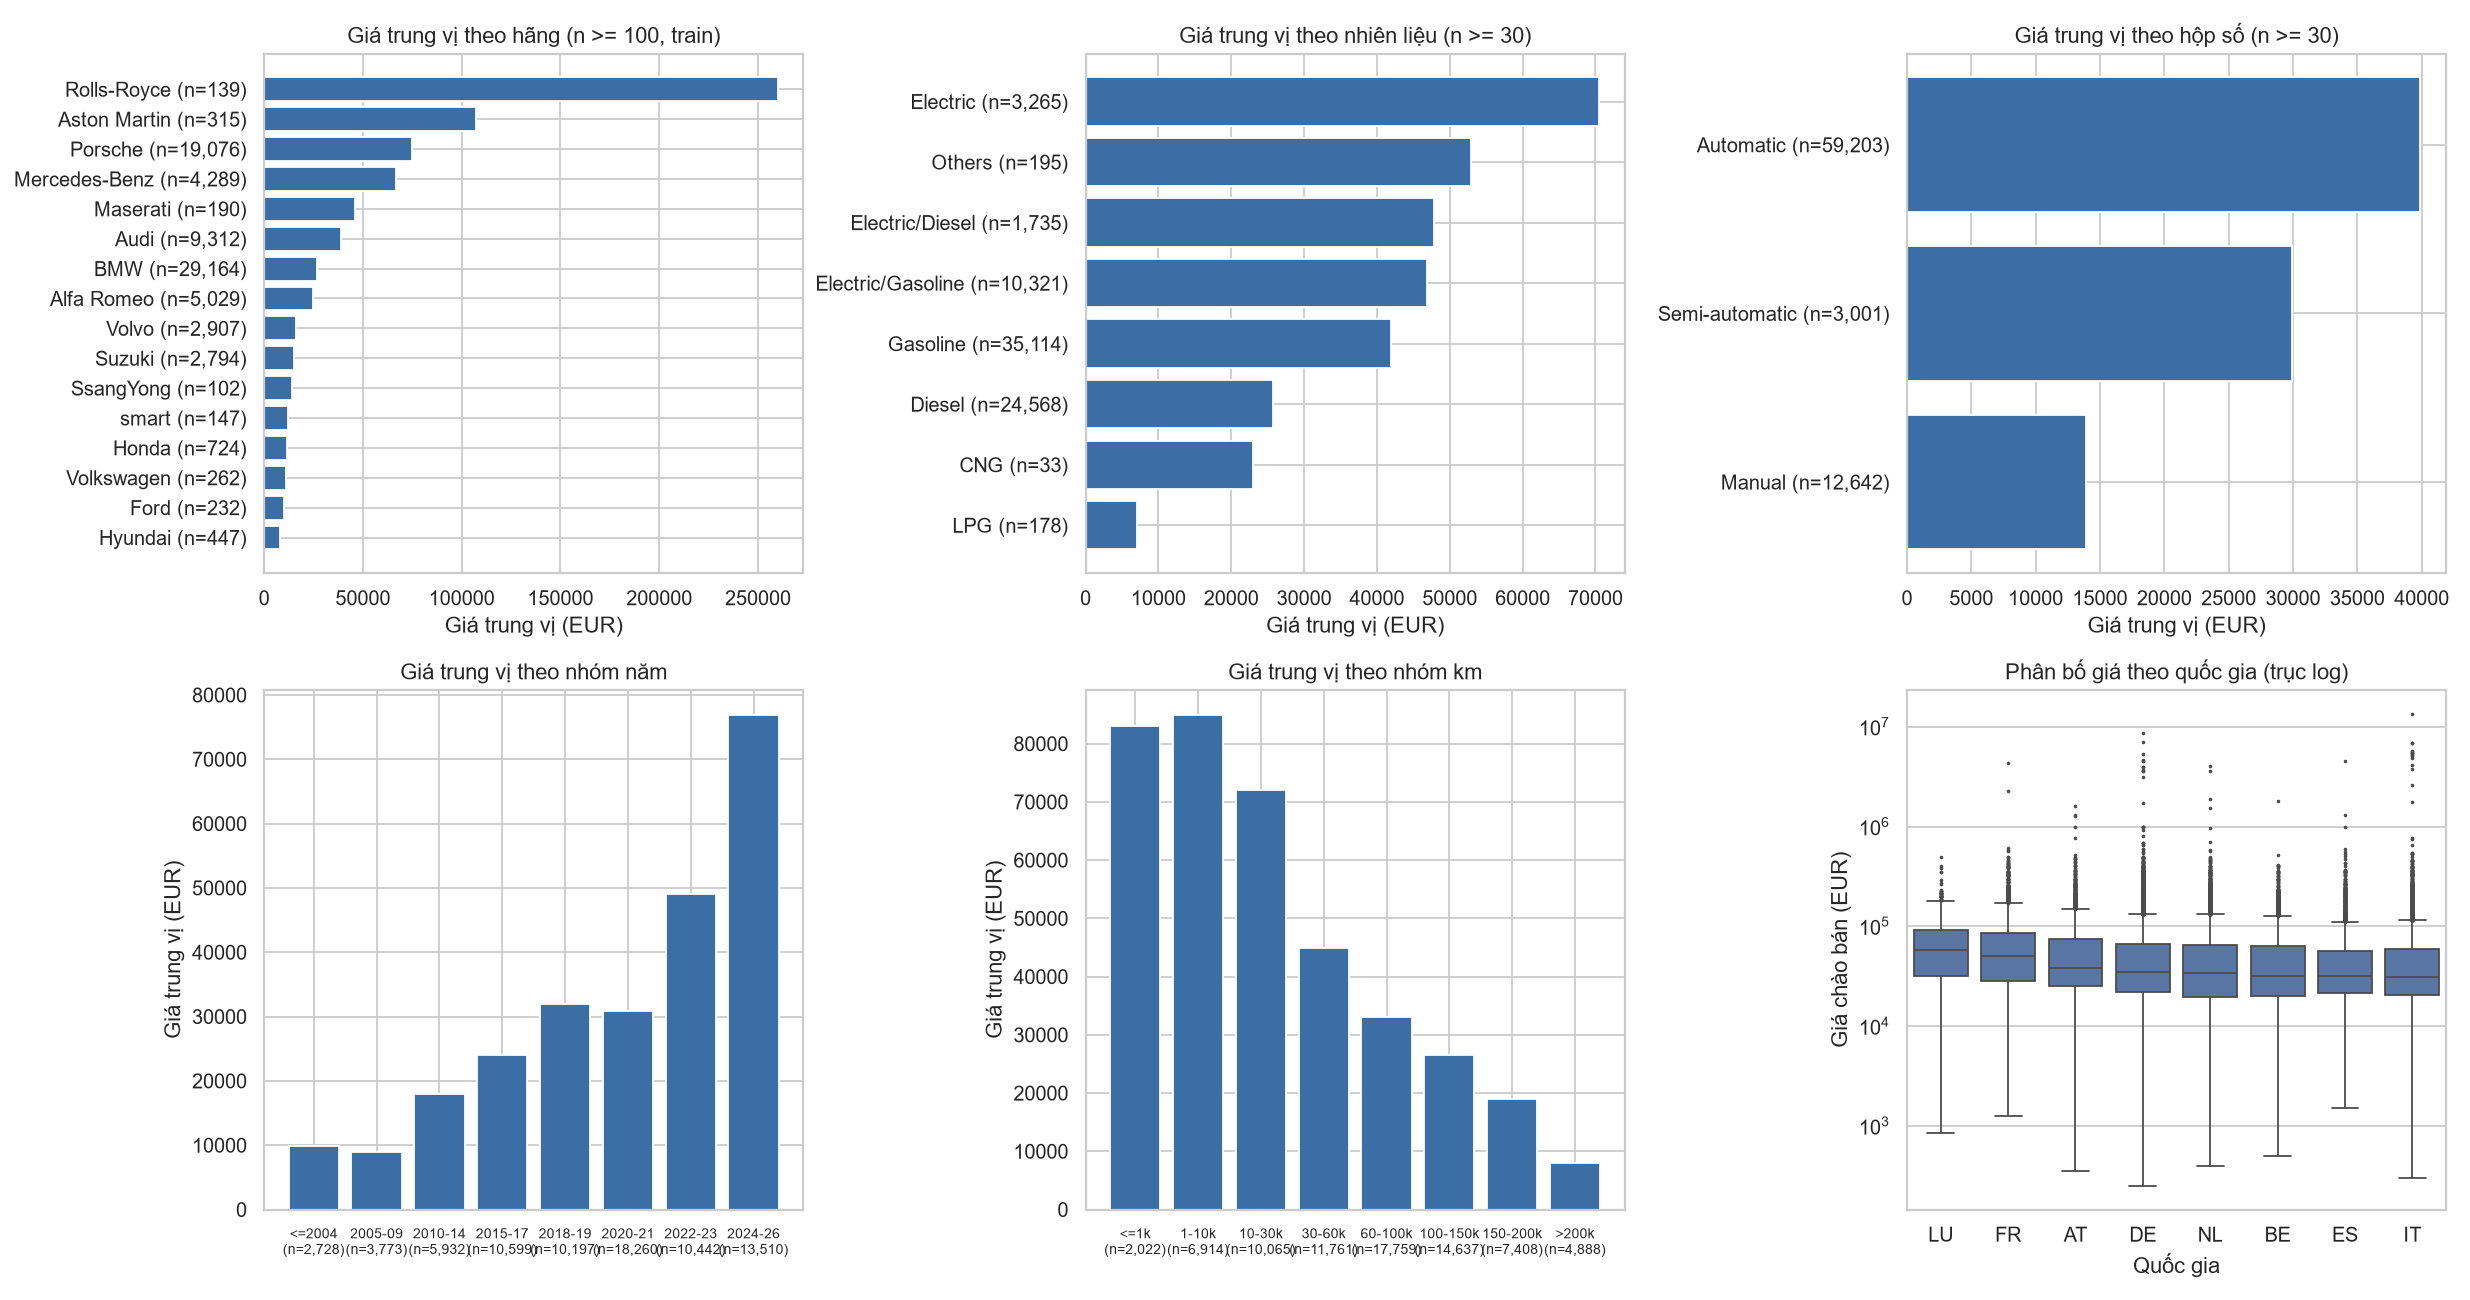

median_price_by_brand


,brand,n,median
0,Rolls-Royce,139,"259,900.00"
1,Aston Martin,315,"107,007.00"
2,Porsche,19076,"74,990.00"
3,Mercedes-Benz,4289,"66,640.00"
4,Maserati,190,"45,900.00"
5,Audi,9312,"38,990.00"
6,BMW,29164,"27,000.00"
7,Alfa Romeo,5029,"24,950.00"
8,Volvo,2907,"16,000.00"
9,Suzuki,2794,"14,950.00"


median_price_by_fuel_type


,fuel_type,n,median
0,Electric,3265,"70,480.00"
1,Others,195,"52,889.00"
2,Electric/Diesel,1735,"47,900.00"
3,Electric/Gasoline,10321,"46,850.00"
4,Gasoline,35114,"41,890.00"
5,Diesel,24568,"25,700.00"
6,CNG,33,"23,000.00"
7,LPG,178,"7,000.00"


median_price_by_transmission


,transmission,n,median
0,Automatic,59203,"39,900.00"
1,Semi-automatic,3001,"29,900.00"
2,Manual,12642,"13,900.00"


median_price_by_country


,country_code,n,median
0,LU,600,"58,245.00"
1,FR,4802,"49,990.00"
2,AT,4733,"38,000.00"
3,DE,26061,"34,980.00"
4,NL,9852,"33,945.00"
5,BE,6865,"31,999.00"
6,ES,5556,"31,999.00"
7,IT,16978,"30,900.00"


In [9]:
display(Image(str(ROOT / 'reports/figures/price_relationships.png')))
for name in ['median_price_by_brand','median_price_by_fuel_type','median_price_by_transmission','median_price_by_country']:
    print(name); display(pd.read_csv(T / f'{name}.csv').head(12))

In [10]:
display(pd.read_csv(T / 'country_summary.csv'))

,country_code,n,median_price,p10,p90,share_pct,flag_small_sample
0,DE,32516,"34,970.00","11,950.00","109,900.00",34.49,False
1,IT,21181,"30,900.00","10,600.00","98,911.00",22.47,False
2,NL,12381,"33,945.00","6,250.00","119,911.00",13.13,False
3,BE,8525,"32,450.00","12,966.00","107,900.00",9.04,False
4,ES,6887,"32,228.00","15,990.00","95,200.00",7.31,False
5,FR,6057,"49,990.00","17,990.00","145,870.00",6.43,False
6,AT,5974,"38,500.00","16,262.00","116,975.00",6.34,False
7,LU,733,"59,890.00","19,000.00","154,998.00",0.78,True
8,NaN,12,"49,995.00","29,540.00","169,955.00",0.01,True


Giá theo quốc gia bị nhiễu bởi cơ cấu hãng/xe khác nhau; các nhóm n nhỏ (Luxembourg, LPG, CNG…) không đủ cơ sở kết luận.

## 7. Kết luận EDA

In [11]:
fl = stats['flags']; sp = stats['split']
print('Số xe cũ sạch:', f"{stats['n_clean']:,}", '| train/test:', sp['n_train'], '/', sp['n_test'])
print('Cờ giá cần xem xét:', fl['price_review'], '| năm suy từ:', fl['year_source'])
print('Random split sẽ rò rỉ:', stats['random_split_leak'])

Số xe cũ sạch: 94,266 | train/test: 75457 / 18809
Cờ giá cần xem xét: 6 | năm suy từ: {'registration_date': 82793, 'production_year': 11453, 'missing': 20}
Random split sẽ rò rỉ: {'test_rows_with_same_group_in_train': 860, 'n_test': 18854, 'group_split_same_metric': 0}


**Đặc trưng đáng giữ:** brand, model (make_model), fuel_type, transmission, body_type, country_code, seller_type, drive_train, body_color, production_year/vehicle_age, mileage_km, power_kw, engine_cc, nr_seats. `model_version` là biến thí nghiệm cardinality riêng.

**Vấn đề dữ liệu:** `production_year` gốc thiếu ~81% (suy từ ngày đăng ký); drive_train/body_color thiếu nhiều; giá lệch rất mạnh, có vài giá nghi lỗi; trạng thái xe không nhất quán ở ~14,7 nghìn tin (đã loại); dữ liệu thiên về xe cao cấp.

**Giả thuyết cho tuần 2–3 (cần kiểm chứng):** (1) log-target cải thiện RMSE/MAE tương đối cho mô hình tuyến tính; (2) One-hot + Ridge tốt nhưng chiều lớn khi có model_version; (3) KNN/SVR nhạy cảm với scaling và với encoding có chiều lớn; (4) Random Forest ít phụ thuộc scaling; (5) Target encoding cải thiện nếu và chỉ nếu fit trong fold, có smoothing.

**Quyết định cần tránh (leakage):** dùng `price_net`/`price_vat_rate`; fit imputer/scaler/encoder trước khi chia; dùng test để chọn đặc trưng; random split bỏ qua nhóm xe trùng; đưa VIN/id/tên người bán vào mô hình.